# VALORA AI — EDA & Machine Learning Modeling
**Project:** Apartment asking-price estimation in Montenegro  
**Goal:** Explore the dataset, clean records, and prepare real apartment listings for regression modeling.  
**Dataset:** 1,986 real listings and 2,000 simulated records. Simulated records are excluded from this real-listing EDA. Asking prices are not confirmed transaction prices.  
**Language:** Column names are translated into English in the notebook; place names and original property-type values remain as recorded in the source data.


## 1. Load and inspect the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

In [2]:
# Upload the dataset
uploaded = files.upload()

Saving Valora_AI_Dataset.csv to Valora_AI_Dataset.csv


In [3]:
# Read the dataset
filename = next(iter(uploaded))
df = pd.read_csv(filename)
# Use English column names throughout the notebook
df = df.rename(columns={'izvor': 'source', 'tip': 'property_type', 'cijena_eur': 'price_eur', 'povrsina_m2': 'area_m2', 'cijena_po_m2': 'price_per_m2_original', 'sobe': 'bedrooms', 'kupatila': 'bathrooms', 'lokacija': 'location', 'grad': 'city', 'naslov': 'title', 'opis': 'description', 'provjera': 'verification'})
df.shape

(3986, 19)

This dataset contains 3,986 rows and 19 columns. Each row represents one property record.


In [4]:
# Check the first 5 rows
df.head()

,listing_id,source,property_type,price_eur,area_m2,price_per_m2_original,bedrooms,bathrooms,location,city,title,url,description,verification,data_origin,simulated_condition,simulated_year_built,simulated_floor,simulated_land_area_m2
0,2778761,Realitica,kuća,650000.0,250.0,2600.00,NaN,NaN,"Bar, Bar,",NaN,"kuću 3 sobe, 250 m2, €650.000 Bar, Bar,",https://www.realitica.com/hr/listing/2778761,NaN,OK,REAL,NaN,NaN,NaN,NaN
1,2961851,Realitica,kuća,520000.0,95.0,5473.68,NaN,NaN,"Baošići,",NaN,"kuću 3 sobe, 95 m2, €520.000 Baošići,",https://www.realitica.com/hr/listing/2961851,NaN,OK,REAL,NaN,NaN,NaN,NaN
2,3000522,Realitica,kuća,580000.0,314.0,1847.13,NaN,NaN,"Bijela,",NaN,"kuću 8 sobe, 314 m2, €580.000 Bijela,",https://www.realitica.com/hr/listing/3000522,NaN,OK,REAL,NaN,NaN,NaN,NaN
3,3000970,Realitica,kuća,580000.0,285.0,2035.09,NaN,NaN,"Đenovići,",NaN,"kuću 285 m2, €580.000 Đenovići,",https://www.realitica.com/hr/listing/3000970,NaN,OK,REAL,NaN,NaN,NaN,NaN
4,3001059,Realitica,kuća,320000.0,149.0,2147.65,NaN,NaN,"Podi,",NaN,"kuću 3 sobe, 149 m2, €320.000 Podi,",https://www.realitica.com/hr/listing/3001059,NaN,OK,REAL,NaN,NaN,NaN,NaN


Here I can see the first five properties and the information available for each one.

In [5]:
# Check the columns and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3986 entries, 0 to 3985
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   listing_id              3986 non-null   object 
 1   source                  3986 non-null   object 
 2   property_type           3984 non-null   object 
 3   price_eur               3986 non-null   float64
 4   area_m2                 3986 non-null   float64
 5   price_per_m2_original   3986 non-null   float64
 6   bedrooms                3454 non-null   float64
 7   bathrooms               386 non-null    float64
 8   location                3986 non-null   object 
 9   city                    3898 non-null   object 
 10  title                   3986 non-null   object 
 11  url                     1986 non-null   object 
 12  description             549 non-null    object 
 13  verification            3986 non-null   object 
 14  data_origin             3986 non-null   

This shows the column names, data types and how many values are filled in.

In [6]:
# Check for missing values
df.isnull().sum()

,0
listing_id,0
source,0
property_type,2
price_eur,0
area_m2,0
price_per_m2_original,0
bedrooms,532
bathrooms,3600
location,0
city,88


This table shows missing values in each column. I will check the important columns before cleaning the data.

In [7]:
# Check the summary statistics
df.describe()

,price_eur,area_m2,price_per_m2_original,bedrooms,bathrooms,simulated_year_built,simulated_floor,simulated_land_area_m2
count,3.986000e+03,3986.000000,3.986000e+03,3454.000000,386.000000,2000.000000,2000.000000,1000.000000
mean,2.366658e+05,117.355521,4.299608e+03,2.814708,1.316062,1996.921500,3.097000,823.213000
std,3.324074e+05,83.402864,6.713776e+04,1.544533,0.570806,17.313411,2.190888,408.121105
min,1.200000e+03,1.000000,5.130000e+00,0.000000,1.000000,1965.000000,0.000000,100.000000
25%,1.050000e+05,58.000000,9.745200e+02,2.000000,1.000000,1982.000000,1.000000,471.250000
50%,1.575000e+05,92.000000,1.852940e+03,3.000000,1.000000,1998.000000,3.000000,842.000000
75%,2.500000e+05,149.000000,2.997767e+03,4.000000,2.000000,2012.000000,4.000000,1185.250000
max,5.900000e+06,882.000000,3.000000e+06,20.000000,5.000000,2026.000000,8.000000,1499.000000


This table gives a quick summary of the numbers. Mean is the average, 50% is the median, and min and max show the smallest and largest values. Very high or low values might need checking.

In [8]:
# Check for duplicate rows
df.duplicated().sum()

np.int64(0)

This tells me how many rows are exactly the same. The same property can still appear more than once with slightly different details.

## 2. Initial data inspection

In [9]:
print('Columns:', df.columns.tolist())
print('Data origins:')
print(df['data_origin'].value_counts(dropna=False))
print('Property types:')
print(df['property_type'].value_counts(dropna=False))
print('Missing values:')
print(df.isna().sum().sort_values(ascending=False))
display(df.describe(include='all').T)


Columns: ['listing_id', 'source', 'property_type', 'price_eur', 'area_m2', 'price_per_m2_original', 'bedrooms', 'bathrooms', 'location', 'city', 'title', 'url', 'description', 'verification', 'data_origin', 'simulated_condition', 'simulated_year_built', 'simulated_floor', 'simulated_land_area_m2']
Data origins:
data_origin
SIMULATED    2000
REAL         1986
Name: count, dtype: int64
Property types:
property_type
stan                 1967
kuća                 1408
Stan                  506
Kuća                   28
nepoznato              17
nejasno                14
ostalo/nepoznato       12
kuća (provjeriti)      12
Kuća/Vila               8
Nepoznato               6
NaN                     2
vila                    2
kuca                    2
Kuca                    2
Name: count, dtype: int64
Missing values:
bathrooms                 3600
description               3437
simulated_land_area_m2    2986
url                       2000
simulated_condition       1986
simulated_floor       

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
listing_id,3986,3986,SIM-H1000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source,3986,4,SIMULATED,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
property_type,3984,13,stan,1967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price_eur,3986.0,NaN,NaN,NaN,236665.840692,332407.38901,1200.0,105000.0,157500.0,250000.0,5900000.0
area_m2,3986.0,NaN,NaN,NaN,117.355521,83.402864,1.0,58.0,92.0,149.0,882.0
price_per_m2_original,3986.0,NaN,NaN,NaN,4299.608287,67137.758036,5.13,974.52,1852.94,2997.7675,3000000.0
bedrooms,3454.0,NaN,NaN,NaN,2.814708,1.544533,0.0,2.0,3.0,4.0,20.0
bathrooms,386.0,NaN,NaN,NaN,1.316062,0.570806,1.0,1.0,1.0,2.0,5.0
location,3986,286,"Budva,",133,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,3898,200,Podgorica,601,NaN,NaN,NaN,NaN,NaN,NaN,NaN


These tables show the types of properties, where the data came from, missing values and a general summary of all columns.

## 3. Data cleaning and selecting real apartments
Standardize property-type labels, exclude simulated records, and filter unusual values. The price and area thresholds are modeling choices, not official market limits.


In [10]:
work = df.copy()
work['property_type_clean'] = work['property_type'].astype('string').str.strip().str.lower()
work['data_origin'] = work['data_origin'].astype('string').str.strip().str.upper()
work['price_eur'] = pd.to_numeric(work['price_eur'], errors='coerce')
work['area_m2'] = pd.to_numeric(work['area_m2'], errors='coerce')
work['bedrooms'] = pd.to_numeric(work['bedrooms'], errors='coerce')

real = work[(work['data_origin'] == 'REAL') & (work['property_type_clean'].isin(['stan', 'apartment']))].copy()
print('Real apartment rows before cleaning:', len(real))
real = real.drop_duplicates(subset=['source', 'listing_id'])
real = real[(real['price_eur'].between(10000, 2000000)) & (real['area_m2'].between(15, 350))].copy()
real['price_per_m2'] = real['price_eur'] / real['area_m2']
real = real[real['price_per_m2'].between(300, 15000)].copy()
print('Real apartment rows after cleaning:', len(real))
print('Missing city:', real['city'].isna().sum())
display(real[['city','location','area_m2','bedrooms','price_eur','price_per_m2']].head())

Real apartment rows before cleaning: 1473
Real apartment rows after cleaning: 1432
Missing city: 3


,city,location,area_m2,bedrooms,price_eur,price_per_m2
95,stan 1 sobe,"Đenovići,",59.0,1.0,154000.0,2610.169492
96,stan 5 sobe,"Meljine,",230.0,5.0,1520000.0,6608.695652
97,Kotor,"Kotor, Kotor,",58.0,1.0,320000.0,5517.241379
98,stan 2 sobe,"Baošići,",93.0,2.0,220000.0,2365.591398
99,stan 3 sobe,"Herceg Novi,",178.0,3.0,550000.0,3089.887640


This table shows a few apartments after cleaning. I kept real apartment listings and removed some records with unrealistic prices or sizes. I can also see the price per square meter.

I selected only real apartment listings and removed duplicates and unusual prices and sizes.

Before cleaning, there were 1,473 apartments. After cleaning, 1,432 remained.

Only 3 records have missing city values. However, some city names are incorrect and need to be cleaned before modeling.

## 4. EDA — prices, apartment size, and location

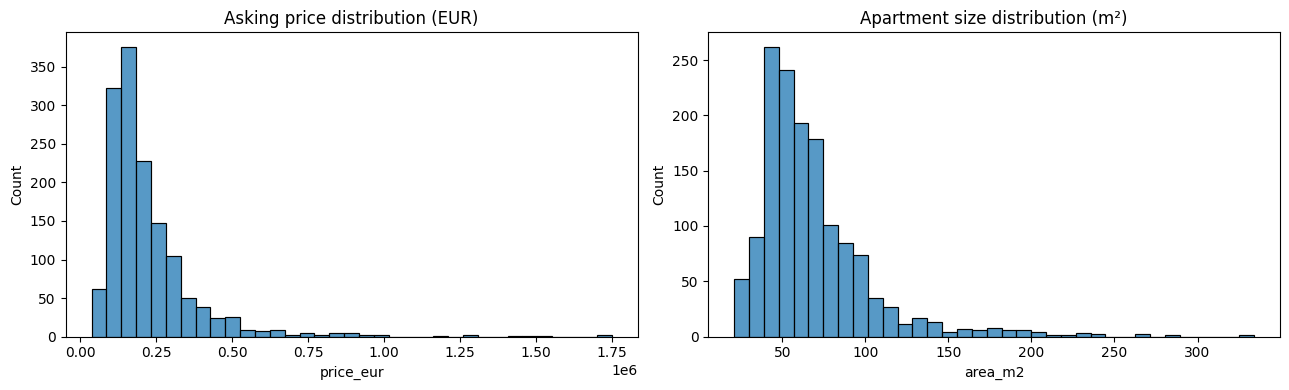

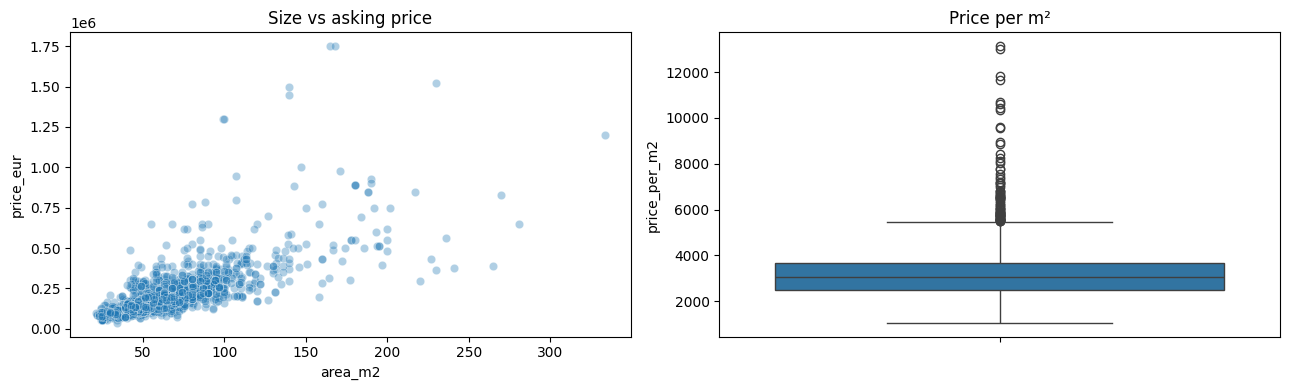

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(real['price_eur'], bins=35, ax=axes[0]); axes[0].set_title('Asking price distribution (EUR)')
sns.histplot(real['area_m2'], bins=35, ax=axes[1]); axes[1].set_title('Apartment size distribution (m²)')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(data=real, x='area_m2', y='price_eur', alpha=.35, ax=axes[0])
axes[0].set_title('Size vs asking price')
sns.boxplot(data=real, y='price_per_m2', ax=axes[1]); axes[1].set_title('Price per m²')
plt.tight_layout(); plt.show()

(1)The first charts show how prices and apartment sizes are distributed.

(2)Apartment Size Distribution. Most apartments are between 40 and 80 m². Larger apartments are less common, and only a few are over 200 m².

(3)The scatter plot compares size and price. The scatter plot shows a positive relationship between property size and price. Larger properties usually cost more, but there are some outliers with much higher prices.

(4)The box plot shows that most property prices are around €3,000 per m². There are several outliers with much higher prices that should be checked before modeling.

Top city values (check data quality):


,count
city,
Podgorica,494
stan 1 sobe,200
stan 2 sobe,177
Kolašin,55
stan 3 sobe,55
Ulcinj,49
Tivat,45
Cetinje,26
Centar,25


City coverage:


,count
city_model,
Podgorica,501
Unknown,297
Budva,196
Bar,83
Tivat,76
Kotor,67
Kolašin,59
Ulcinj,56
Cetinje,33


,listings,median_eur_m2
city_model,,
Tivat,76,4000.000000
Kotor,67,3783.783784
Budva,196,3500.000000
Unknown,297,3333.333333
Herceg Novi,19,3071.428571
Bar,83,2948.717949
Žabljak,16,2854.551920
Podgorica,501,2833.333333
Kolašin,59,2500.000000


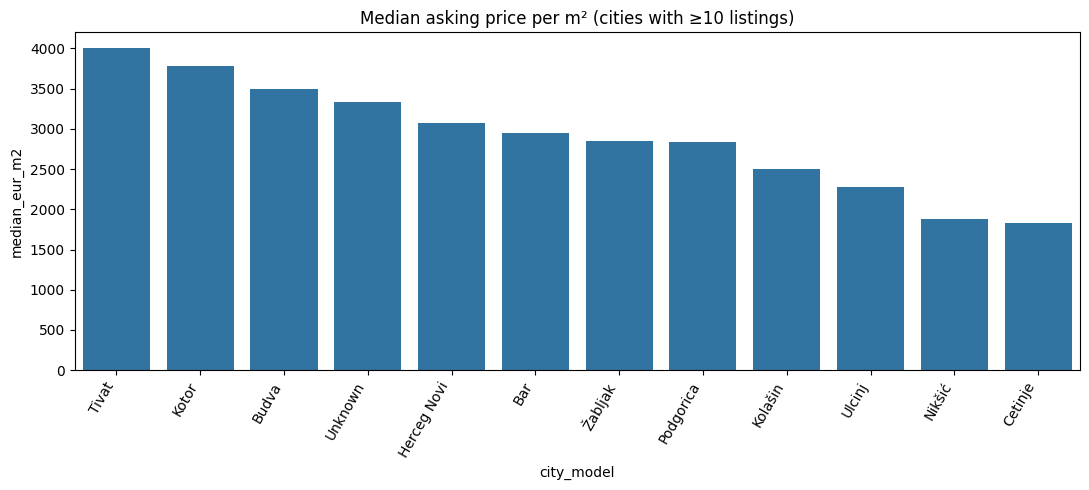

In [12]:
print('Top city values (check data quality):')
display(real['city'].value_counts(dropna=False).head(15))
valid_cities = ['Podgorica','Budva','Bar','Kotor','Tivat','Herceg Novi','Ulcinj','Nikšić','Niksic','Cetinje','Kolašin','Kolasin','Žabljak','Zabljak','Bijelo Polje','Berane','Danilovgrad','Pljevlja','Plav','Rožaje','Rozaje','Mojkovac','Petnjica','Tuzi','Zeta','Andrijevica','Šavnik','Savnik','Plužine','Pluzine','Gusinje']
real['city_model'] = real['city'].where(real['city'].isin(valid_cities))
# Fill city only when it appears explicitly in the location text.
for city in valid_cities:
    mask = real['city_model'].isna() & real['location'].fillna('').str.contains(city, case=False, regex=False)
    real.loc[mask, 'city_model'] = city
real['city_model'] = real['city_model'].fillna('Unknown')
print('City coverage:')
display(real['city_model'].value_counts().head(15))

city_stats = real.groupby('city_model').agg(listings=('price_eur','size'), median_eur_m2=('price_per_m2','median')).query('listings >= 10').sort_values('median_eur_m2', ascending=False)
display(city_stats)
plt.figure(figsize=(11,5)); sns.barplot(x=city_stats.index, y=city_stats['median_eur_m2']); plt.xticks(rotation=60, ha='right'); plt.title('Median asking price per m² (cities with ≥10 listings)'); plt.tight_layout(); plt.show()

The first tables show how many apartments we have in each city. The next table compares the median price per square meter, using cities with at least 10 listings. The bar chart makes these differences easier to see.

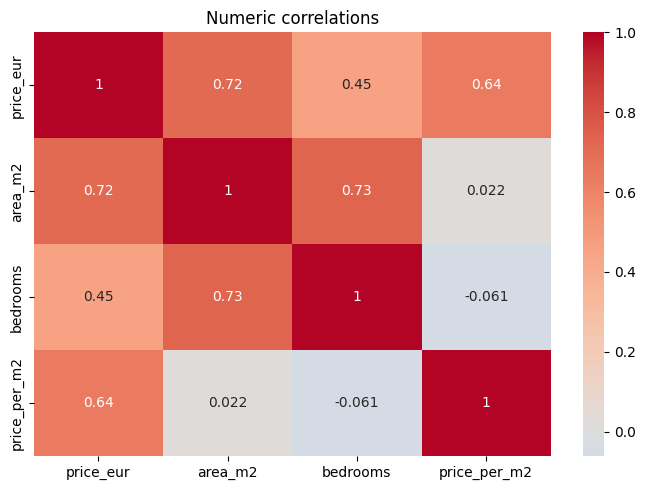

In [13]:
numeric_cols = ['price_eur', 'area_m2', 'bedrooms', 'price_per_m2']
plt.figure(figsize=(7,5)); sns.heatmap(real[numeric_cols].corr(), annot=True, cmap='coolwarm', center=0); plt.title('Numeric correlations'); plt.tight_layout(); plt.show()

This chart shows correlations between the numeric columns. Values close to 1 mean a positive relationship, values close to -1 mean a negative relationship, and values close to 0 mean a weak linear relationship.

**Correlation Heatmap**

The heatmap shows the relationships between numerical features.

- Price and area have a strong positive correlation (0.72).
- Area and bedrooms also have a strong correlation (0.73).
- Price and bedrooms have a moderate correlation (0.45).
- Area and price per m² have almost no correlation (0.02).

**Conclusion:** Property size is strongly related to total price, making it an important feature for price prediction.

## 5. Conclusion and limitations
After running the notebook, fill in:
- **Sample:** ___ real apartments after cleaning.
- **EDA:** City with the highest median asking price per m² among cities with at least 10 listings: ___.
- **Limitations:** Asking prices are not final sale prices; some city labels are missing or inconsistent; duplicates may occur across sources; simulated records are excluded from the real-listing analysis.
- **Next step:** Train and evaluate a regression model using the cleaned real listings. A 6-month forecast would require separate historical data.

**Data transparency:** The source CSV includes 2,000 simulated records, which must not be presented as actual property listings.
